<a href="https://colab.research.google.com/github/luciancj/cuda-gemm-lab/blob/main/notebooks/colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# cuda-gemm-lab on Colab

Runs the SGEMM kernel ladder: build, check every kernel against cuBLAS, benchmark, plot.

**First:** Runtime → Change runtime type → **T4 GPU** (or any GPU).

In [1]:
!nvidia-smi

Sun Oct 25 14:02:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
REPO_URL = "https://github.com/luciancj/cuda-gemm-lab.git"  # change if your fork lives elsewhere
import os
if os.path.isdir("cuda-gemm-lab/.git"):
    !git -C cuda-gemm-lab pull -q
else:
    !git clone -q {REPO_URL}
assert os.path.isdir("cuda-gemm-lab"), f"clone failed: is {REPO_URL} pushed and public?"
%cd cuda-gemm-lab

/content/cuda-gemm-lab


Compile for whichever GPU Colab gave us (T4 = `sm_75`, L4 = `sm_89`, A100 = `sm_80`).

In [3]:
import subprocess
cc = subprocess.check_output(
    ["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"], text=True
).split()[0]
ARCH = "sm_" + cc.replace(".", "")
print(ARCH)

sm_75


In [4]:
!make ARCH={ARCH} && make test ARCH={ARCH}

nvcc -O3 -std=c++17 -lineinfo -arch=sm_75 -o build/sgemm src/main.cu -lcublas
./build/sgemm all 128 256x384x128 384x128x264 97x131x77 > /dev/null
# GPU: Tesla T4 (sm_75)
# skip blocktile_1d at 97x131x77: needs multiples of 64x64x8
# skip blocktile_2d at 97x131x77: needs multiples of 128x128x8
# skip vectorized at 97x131x77: needs multiples of 128x128x8
all kernels match cuBLAS


## Benchmark

The naive kernel at 4096³ takes a while; that is the point.

In [5]:
!make bench ARCH={ARCH}

./build/sgemm all | tee results/bench.csv
# GPU: Tesla T4 (sm_75)
kernel_id,kernel,M,N,K,ms,gflops,pct_cublas,max_abs_err
0,cublas,256,256,256,0.0375,895.0,100.0,0.00e+00
1,naive,256,256,256,1.3765,24.4,2.7,1.91e-05
2,coalesced,256,256,256,0.0979,342.8,38.3,1.91e-05
3,smem_tiling,256,256,256,0.0808,415.0,46.4,1.91e-05
4,blocktile_1d,256,256,256,0.0617,544.1,60.8,1.91e-05
5,blocktile_2d,256,256,256,0.1458,230.1,25.7,1.91e-05
6,vectorized,256,256,256,0.1225,274.0,30.6,1.91e-05
0,cublas,512,512,512,0.0988,2718.2,100.0,0.00e+00
1,naive,512,512,512,9.1764,29.3,1.1,3.81e-06
2,coalesced,512,512,512,0.6806,394.4,14.5,3.81e-06
3,smem_tiling,512,512,512,0.5499,488.2,18.0,3.81e-06
4,blocktile_1d,512,512,512,0.2722,986.3,36.3,3.81e-06
5,blocktile_2d,512,512,512,0.2775,967.2,35.6,3.81e-06
6,vectorized,512,512,512,0.2460,1091.2,40.1,3.81e-06
0,cublas,1024,1024,1024,0.6382,3365.1,100.0,0.00e+00
1,naive,1024,1024,1024,35.4707,60.5,1.8,1.18e-04
2,coalesced,1024,1024,1024,2.9321,732.4,21.8,1.18e-04
3,sm

wrote results/bench.png

| # | kernel | GFLOPS @ 4096 | % of cuBLAS |
|---|---|---|---|
| 0 | cublas | 3952 | 100.0% |
| 1 | naive | 62 | 1.6% |
| 2 | coalesced | 522 | 13.2% |
| 3 | smem_tiling | 794 | 20.1% |
| 4 | blocktile_1d | 1674 | 42.3% |
| 5 | blocktile_2d | 2860 | 72.4% |
| 6 | vectorized | 3171 | 80.2% |


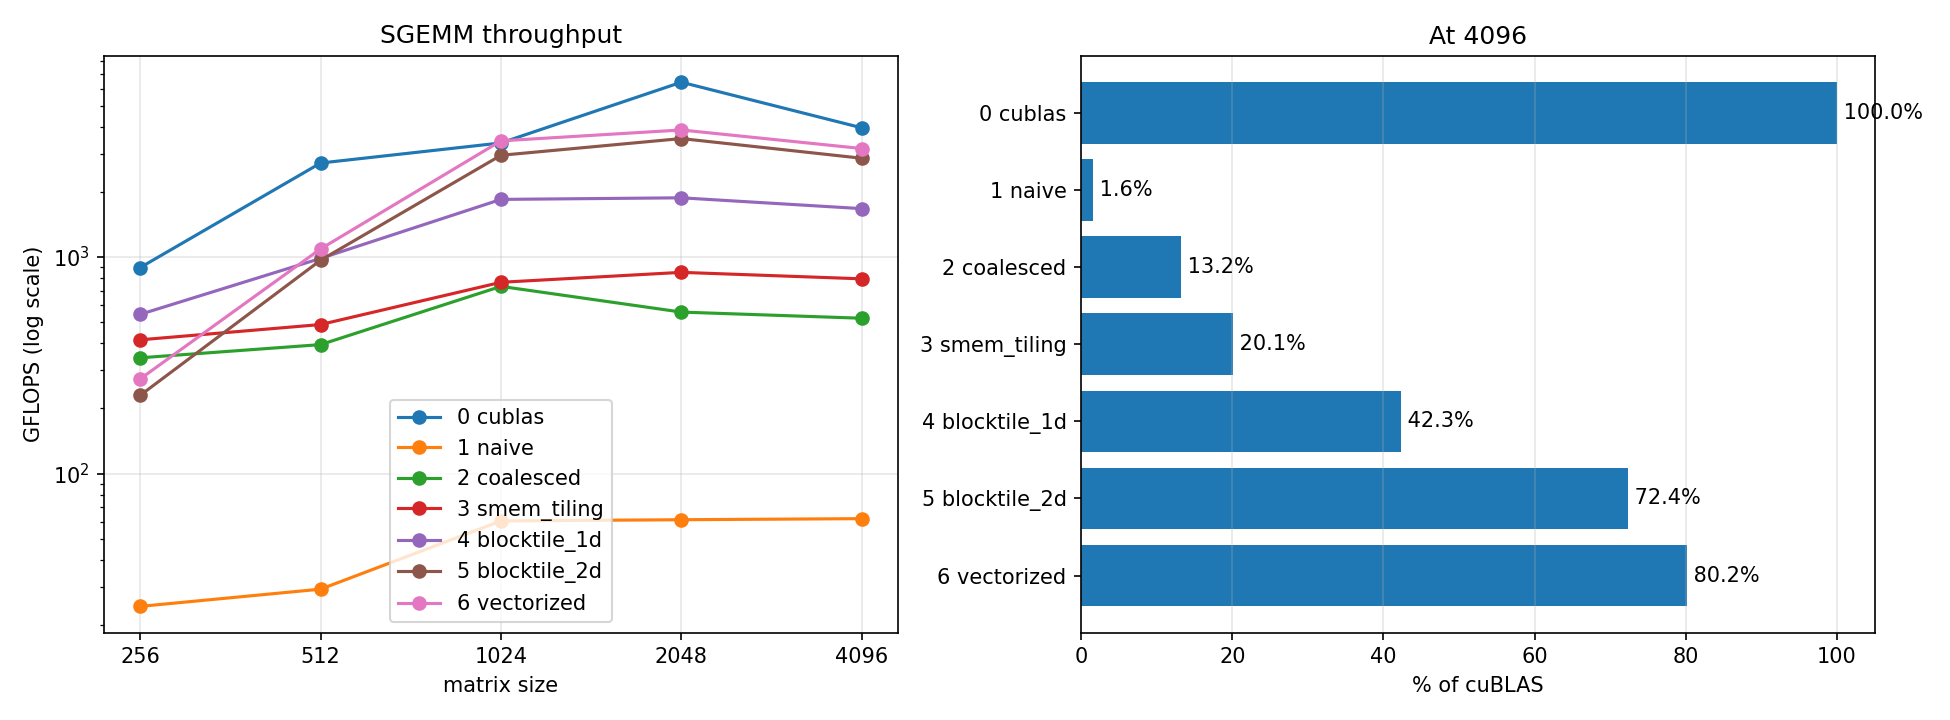

In [6]:
!python scripts/plot.py results/bench.csv results/bench.png
from IPython.display import Image
Image("results/bench.png")

## Optional: profile one kernel with Nsight Compute

Colab sometimes blocks GPU performance counters (`ERR_NVGPUCTRPERM`); if so, skip this.
Compare `smem_tiling` (3) against `blocktile_2d` (5): look at *Memory Workload Analysis* and *Warp State Statistics*.

In [7]:
!ncu --section SpeedOfLight --section MemoryWorkloadAnalysis -k regex:sgemm --launch-count 1 ./build/sgemm 5 2048

==PROF== Connected to process 1387 (/content/cuda-gemm-lab/build/sgemm)
# GPU: Tesla T4 (sm_75)
kernel_id,kernel,M,N,K,ms,gflops,pct_cublas,max_abs_err
==PROF== Profiling "volta_sgemm_128x64_nn": 0%....50%....100% - 9 passes
5,blocktile_2d,2048,2048,2048,6.2855,2733.3,60.4,2.82e-04
==PROF== Disconnected from process 1387
[1387] sgemm@127.0.0.1
  volta_sgemm_128x64_nn (16, 32, 2)x(128, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         5.00
    SM Frequency                    Mhz       600.00
    Elapsed Cycles                cycle    3,529,093
    Memory Throughput                 %        43.16
    DRAM Throughput                   %        18.62
    Duration                         ms         5.88
    L1/TEX Cache Throughput           %        